# First Python lab: probabilities to generation

This small experiment connects a familiar categorical model to the sampling step used in language generation. It runs on a CPU with NumPy and Matplotlib, with no model download or API account.

<a href="https://chikuang.github.io/teaching/genai/notebooks/01-python-lab.ipynb" download>Download the Jupyter notebook</a>

The web page displays results computed by Python when the course is built. To edit and run the cells yourself, open the downloaded notebook in JupyterLab or VS Code; the static web page does not run a Python kernel.

## 1 · Represent a probability distribution

Suppose a toy model predicts the next token from a vocabulary of three words. These probabilities are supplied for illustration; we have not trained a language model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

tokens = np.array(["statistics", "learning", "agents"])
p = np.array([0.60, 0.30, 0.10])
assert np.isclose(p.sum(), 1.0)
print(dict(zip(tokens.tolist(), p.tolist())))

{'statistics': 0.6, 'learning': 0.3, 'agents': 0.1}


`np.array` creates a numerical array. Python indexing starts at zero, so `p[0]` is the first probability. `np.isclose` compares floating-point values with a tolerance. `assert` stops execution if a check fails.

## 2 · Evaluate log loss

For observations $y_1,\ldots,y_n$ drawn from a categorical distribution, the average negative log likelihood is

$$
\widehat L(p)=-\frac{1}{n}\sum_{i=1}^n\log p_{y_i}.
$$

This is the empirical log loss in Equation [(1.3)](https://chikuang.github.io/teaching/genai/chapters/01-probability-to-genai.html#equation-eq-log-loss) from Chapter 1. Here the observations are token indices. The array `p[observed]` looks up the predicted probability of each observed token.

In [2]:
observed = np.array([0, 0, 1, 0, 2, 1])
model_loss = -np.log(p[observed]).mean()
uniform = np.full(3, 1 / 3)
uniform_loss = -np.log(uniform[observed]).mean()
print(f"Toy model log loss: {model_loss:.3f} nats per token")
print(f"Uniform log loss:   {uniform_loss:.3f} nats per token")

Toy model log loss: 1.041 nats per token
Uniform log loss:   1.099 nats per token


This tiny sample is an illustration of the calculation, not evidence that one model will outperform another on a target population. In a real comparison, choose the model on development data and evaluate on separate held-out observations. Natural logarithms give losses in **nats**.

## 3 · Change the sampling temperature

Given logits $z_j$ and temperature $T>0$, the sampling probabilities are

$$
p_T(j)=\frac{\exp(z_j/T)}{\sum_k\exp(z_k/T)}.
$$

This is the temperature transformation in Equation [(1.7)](https://chikuang.github.io/teaching/genai/chapters/01-probability-to-genai.html#equation-eq-temperature) from Chapter 1. Taking $z_j=\log p_j$ recovers the original distribution at $T=1$. Lower temperatures concentrate probability on higher-scoring tokens. Higher temperatures move this finite-vocabulary distribution toward uniformity. Neither operation establishes that a generated statement is true.

In [3]:
def softmax(logits, temperature=1.0):
    if temperature <= 0:
        raise ValueError("Temperature must be positive.")
    scaled = np.asarray(logits, dtype=float) / temperature
    weights = np.exp(scaled - scaled.max())
    return weights / weights.sum()

logits = np.log(p)
temperatures = [0.5, 1.0, 2.0]
probabilities = np.vstack([softmax(logits, t) for t in temperatures])
assert np.allclose(probabilities.sum(axis=1), 1.0)
assert np.allclose(softmax(logits, 1.0), p)
for t, row in zip(temperatures, probabilities):
    print(f"T={t:.1f}: {np.round(row, 3)}")

T=0.5: [0.783 0.196 0.022]
T=1.0: [0.6 0.3 0.1]
T=2.0: [0.473 0.334 0.193]


Subtracting the maximum before exponentiation leaves softmax unchanged and reduces overflow risk. A function is defined with `def`; indentation defines its body. The list comprehension computes one row for each temperature, and `np.vstack` combines the rows into a matrix.

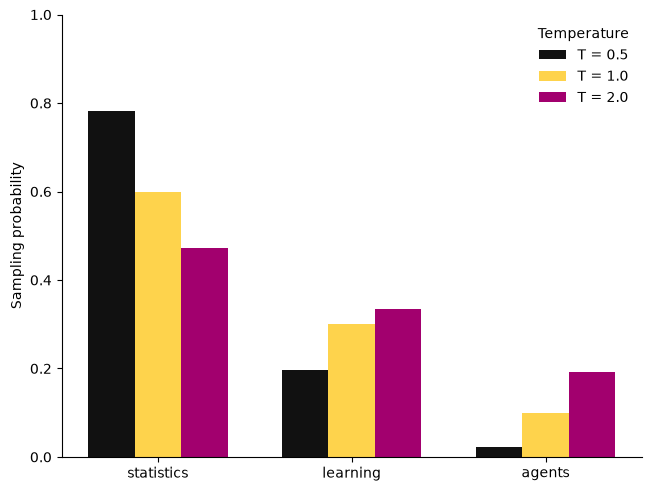

In [4]:
fig, ax = plt.subplots(layout="constrained")
x = np.arange(len(tokens))
width = 0.24
colors = ["#111111", "#FED34C", "#A2006E"]
for i, (t, row, color) in enumerate(zip(temperatures, probabilities, colors)):
    ax.bar(x + (i - 1) * width, row, width, label=f"T = {t}", color=color)
ax.set_xticks(x, tokens)
ax.set_ylabel("Sampling probability")
ax.set_ylim(0, 1)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Temperature", frameon=False)
plt.show()

## 4 · Generate and inspect a Monte Carlo sample

In [5]:
rng = np.random.default_rng(8670)
draws = rng.choice(len(tokens), size=10_000, p=softmax(logits, 1.0))
frequencies = np.bincount(draws, minlength=len(tokens)) / len(draws)
print("Target:   ", p)
print("Observed: ", np.round(frequencies, 3))
print("One draw: ", tokens[draws[0]])

Target:    [0.6 0.3 0.1]
Observed:  [0.592 0.303 0.105]
One draw:  statistics


A fixed seed makes this example reproducible within the recorded environment. Sampling variation remains part of the statistical experiment. These independent draws are a toy example; an autoregressive language model instead updates its conditional distribution after each generated token.

## Try it yourself

1. Change `p` while preserving positivity and a sum of one. Predict the temperature effect before running the code.
2. Repeat the Monte Carlo experiment with smaller sample sizes. Compare observed variability with the multinomial variance formula.
3. Try two different candidate distributions on the same observations. Explain why the lower observed loss alone is not a generalization guarantee.
4. Replace sampling by choosing the highest-probability token. Which aspect of the distribution disappears?

## Bridge to attention

Softmax will return in attention, where it normalizes similarity scores into weights over available positions. The normalization is the same mathematical operation, but its role differs: attention weights combine value vectors, whereas the probabilities above sample an output token. The [statistical lens](https://chikuang.github.io/teaching/genai/statistical-lens.html) introduces the attention equation.